<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV
from sklearn import preprocessing

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error as MSE

In [2]:
url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"
choc = pd.read_csv(url)
choc.head()

,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

<Axes: xlabel='company_location', ylabel='Avg Ratings'>

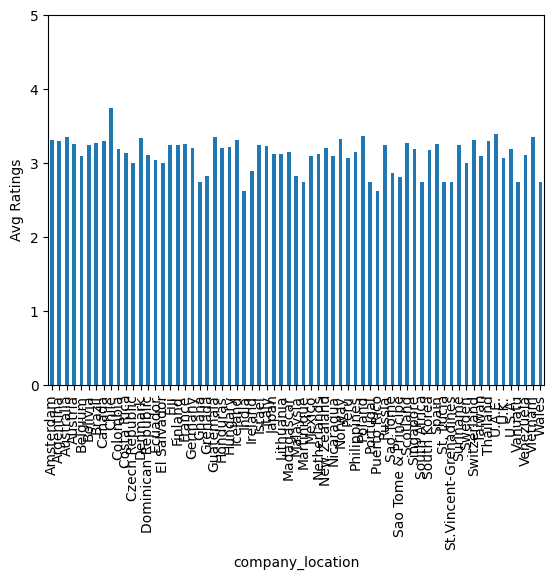

In [4]:
comp = choc.groupby("company_location")["rating"].mean()
ax = comp.plot(kind='bar')
ax.set_ylabel('Avg Ratings')
ax.set_ylim(0, 5)
ax

In [5]:
pd.get_dummies(choc["company_location"], prefix="location")

print(choc["company_location"].unique())
#Possible predictive question: Which factor of chocolate production determines the highest perception of chocolate quality?
#The origin of the bean?  Or the location of manufacturing/which manufacturer.  Which country or region leads to highest perception?

['U.S.A.' 'France' 'Fiji' 'Vanuatu' 'Ecuador' 'Mexico' 'U.K.'
 'Netherlands' 'Spain' 'Russia' 'Peru' 'Canada' 'Italy' 'Brazil'
 'Nicaragua' 'Australia' 'Philippines' 'Wales' 'Belgium' 'Vietnam'
 'Germany' 'Singapore' 'Switzerland' 'Venezuela' 'Malaysia' 'South Korea'
 'Taiwan' 'Puerto Rico' 'Colombia' 'Japan' 'New Zealand' 'Costa Rica'
 'Hungary' 'Amsterdam' 'Scotland' 'Martinique' 'Sao Tome' 'St. Lucia'
 'Argentina' 'Guatemala' 'South Africa' 'Dominican Republic'
 'Sao Tome & Principe' 'Bolivia' 'Portugal' 'Norway' 'Denmark' 'Grenada'
 'Israel' 'India' 'St.Vincent-Grenadines' 'Czech Republic' 'Thailand'
 'Finland' 'Madagascar' 'Sweden' 'Poland' 'Austria' 'Honduras' 'U.A.E.'
 'Lithuania' 'Ireland' 'Chile' 'Ghana' 'Iceland' 'Suriname' 'El Salvador']


In [6]:
pd.get_dummies(choc["country_of_bean_origin"], prefix="origin")

print(choc["country_of_bean_origin"].unique())

['Tanzania' 'Dominican Republic' 'Madagascar' 'Fiji' 'Venezuela' 'Uganda'
 'India' 'Bolivia' 'Peru' 'Panama' 'Colombia' 'Burma' 'Brazil'
 'Papua New Guinea' 'Ecuador' 'Cuba' 'Togo' 'Sao Tome' 'Mexico' 'Vanuatu'
 'Indonesia' 'Trinidad' 'Vietnam' 'Nicaragua' 'Ghana' 'Belize' 'Blend'
 'Jamaica' 'Grenada' 'Guatemala' 'Honduras' 'Costa Rica' 'Haiti' 'Congo'
 'Philippines' 'Solomon Islands' 'Malaysia' 'Sri Lanka' 'Ivory Coast'
 'Gabon' 'Taiwan' 'Puerto Rico' 'Martinique' 'St. Lucia' 'Australia'
 'Liberia' 'Sierra Leone' 'U.S.A.' 'Nigeria' 'St.Vincent-Grenadines'
 'Thailand' 'Tobago' 'Sao Tome & Principe' 'Sumatra' 'El Salvador'
 'Cameroon' 'Samoa' 'China' 'Principe' 'Sulawesi' 'Suriname' 'DR Congo']


In [53]:
# Convert cocoa percentage to numeric
choc["cocoa_numeric"] = (
    choc["cocoa_percent"]
    .str.replace("%", "", regex=False)
    .astype(float))

# Concatenate the dummy variables side-by-side to create a single features DataFrame
X = pd.concat([
    pd.get_dummies(choc["country_of_bean_origin"], prefix="origin"),
    pd.get_dummies(choc["company_location"], prefix="location"),
    pd.get_dummies(choc["ingredients"], prefix="ingredients"),
    choc[["cocoa_numeric", "sentiment_total"]]
], axis=1)

y = choc["rating"].values

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=0)
print(X.shape)
display(X.head())

(2530, 152)


,origin_Australia,origin_Belize,origin_Blend,origin_Bolivia,origin_Brazil,origin_Burma,origin_Cameroon,origin_China,origin_Colombia,origin_Congo,...,"ingredients_4- B,S,C,L","ingredients_4- B,S,C,Sa","ingredients_4- B,S,C,V","ingredients_4- B,S,V,L","ingredients_5- B,S,C,L,Sa","ingredients_5- B,S,C,V,L","ingredients_5-B,S,C,V,Sa","ingredients_6-B,S,C,V,L,Sa",cocoa_numeric,sentiment_total
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,76.0,-0.067784
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,76.0,0.072163
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,76.0,0.433540
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,68.0,-0.568570
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,72.0,-0.450000


In [54]:
# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model on the training data
model.fit(X_train, y_train)

# Evaluate the model on the training data
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print(f"Model successfully trained!")
print(f"Training R^2 Score: {train_r2:.4f}")
print(f"Model successfully tested!")
print(f"Test R^2 Score: {test_r2:.4f}")

Model successfully trained!
Training R^2 Score: 0.7051
Model successfully tested!
Test R^2 Score: 0.3596


In [55]:
#KNN
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
neighbors_list = [1,5,10,50,100]
scaler = preprocessing.StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

weights_list = ['uniform', 'distance']

for weight in weights_list:
    print(f"\nWeighting: {weight}")

    for k in neighbors_list:
        model2 = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight)

        model2.fit(X_train_s, y_train)

        y_train_fit = model2.predict(X_train_s)
        mse_train = np.mean((y_train - y_train_fit) ** 2)

        y_test_fit = model2.predict(X_test_s)
        mse_test = np.mean((y_test - y_test_fit) ** 2)

        cv_scores = cross_val_score(
            model2,
            X_train_s,
            y_train,
            cv=kfold,
            scoring='neg_mean_squared_error')

        mse_cv = -cv_scores.mean()

        print(
            f"k={k:3d} | "
            f"train RMSE={np.sqrt(mse_train):.3f} | "
            f"CV RMSE={np.sqrt(mse_cv):.3f} | "
            f"test RMSE={np.sqrt(mse_test):.3f}"
            )
# print(np.sqrt(mse_train), mse_train)


Weighting: uniform
k=  1 | train RMSE=0.000 | CV RMSE=0.473 | test RMSE=0.445
k=  5 | train RMSE=0.317 | CV RMSE=0.399 | test RMSE=0.394
k= 10 | train RMSE=0.351 | CV RMSE=0.395 | test RMSE=0.392
k= 50 | train RMSE=0.393 | CV RMSE=0.400 | test RMSE=0.382
k=100 | train RMSE=0.395 | CV RMSE=0.399 | test RMSE=0.382

Weighting: distance
k=  1 | train RMSE=0.000 | CV RMSE=0.473 | test RMSE=0.445
k=  5 | train RMSE=0.000 | CV RMSE=0.398 | test RMSE=0.391
k= 10 | train RMSE=0.000 | CV RMSE=0.389 | test RMSE=0.386
k= 50 | train RMSE=0.000 | CV RMSE=0.390 | test RMSE=0.376
k=100 | train RMSE=0.000 | CV RMSE=0.390 | test RMSE=0.377


In [56]:
# # Assuming the column is named 'most_memorable_characteristics'
# # We clean any extra whitespace and then split by comma using .str.get_dummies()
# #We are going to use a ridge to calculate scores for each characteristic
# chars = choc["most_memorable_characteristics"].str.lower().str.get_dummies(sep=",")
# chars = chars.T.groupby(chars.columns.str.strip()).max().T
# C_train, C_test, y_train_c, y_test_c = train_test_split(
#     chars, y, test_size=0.3, random_state=0)
# char_ridge = RidgeCV(alphas = np.logspace(-2,3,30)).fit(C_train,y_train_c)
# sentiment_pred = char_ridge.predict(C_test)
# sentiment_scores = pd.Series(char_ridge.coef_, index=chars.columns).sort_values()
# display(sentiment_scores.head(10))   # most negative
# display(sentiment_scores.tail(10))
# # print("Best alpha:", char_ridge.alpha_)
# # print(f"Train R^2: {char_ridge.score(C_train, y_train_c):.3f}")
# # print(f"Test R^2:  {char_ridge.score(C_test, y_test_c):.3f}")
# # print(f"Test RMSE: {np.sqrt(MSE(y_test_c, sentiment_pred)):.3f}")
# # print(f"Test MAE:  {mean_absolute_error(y_test_c, sentiment_pred):.3f}")


# choc["sentiment_total"] = 0.0          # create the column first, starting at 0

# for index, item in enumerate(choc["most_memorable_characteristics"]):
#     total = 0.0
#     for char in item.split(","):              # "fatty, earthy, nutty,chalky" -> pieces
#         char = char.strip().lower()           # clean each piece to match the score names
#         total += sentiment_scores.get(char, 0)   # look up its score (0 if never seen in training)
#     choc.loc[index, "sentiment_total"] = total

display(choc[["most_memorable_characteristics", "sentiment_total", "rating"]].head())



,0
very bitter,-1.213021
this is not chocolate,-0.809600
high intensity bitter,-0.627340
strong off flavor,-0.601575
dominate off note,-0.575971
pastey,-0.570682
unpleasant,-0.546501
strong chemical,-0.524278
bitter,-0.477826
medicinal,-0.450828


,0
gentle roast,0.275629
unripened fruit,0.276748
cardamon,0.283962
cocoa and coconut,0.283962
cinamon and nutmeg,0.283962
distinct lemon,0.283962
blackberry and cinnamon,0.283962
tangerine,0.287563
black current,0.344119
dark berry,0.364719


,most_memorable_characteristics,sentiment_total,rating
0,"rich cocoa, fatty, bready",-0.067784,3.25
1,"cocoa, vegetal, savory",0.072163,3.50
2,"cocoa, blackberry, full body",0.433540,3.75
3,"chewy, off, rubbery",-0.568570,3.00
4,"fatty, earthy, moss, nutty,chalky",-0.450000,3.00


In [68]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. Word-level scores, fit on TRAINING descriptions only
text_train = choc.loc[C_train.index, "most_memorable_characteristics"]
vec = CountVectorizer(binary=True, stop_words=["and", "notes", "note", "of", "with", "a", "the"])
W_train = vec.fit_transform(text_train)
ridge_w = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(W_train, y_train_c)
word_scores = pd.Series(ridge_w.coef_, index=vec.get_feature_names_out())
analyzer = vec.build_analyzer()          # same word-splitting the vectorizer uses

known_phrases = sentiment_scores[C_train.sum(axis=0) > 0]   # phrases actually seen in training

# 2. Score one phrase: whole phrase -> its words -> 0
def score_phrase(phrase):
    if phrase in known_phrases.index:
        return known_phrases[phrase]
    words = [word_scores[w] for w in analyzer(phrase) if w in word_scores.index]
    if words:
        return np.mean(words)
    return 0.0

# 3. sentiment scoring column
choc["sentiment_total"] = 0.0
for index, item in enumerate(choc["most_memorable_characteristics"]):
    total = 0.0
    for char in item.split(","):
        char = char.strip().lower()
        if char:
            total += score_phrase(char)
    choc.loc[index, "sentiment_total"] = total
display(choc[["most_memorable_characteristics", "sentiment_total", "rating"]].head())

,most_memorable_characteristics,sentiment_total,rating
0,"rich cocoa, fatty, bready",-0.067784,3.25
1,"cocoa, vegetal, savory",0.072163,3.50
2,"cocoa, blackberry, full body",0.433540,3.75
3,"chewy, off, rubbery",-0.568570,3.00
4,"fatty, earthy, moss, nutty,chalky",-0.450000,3.00


In [11]:
# 1. Clean chars by grouping its duplicate columns and summing them
if chars.columns.duplicated().any():
    print("Duplicate characteristic columns found. Aggregating them...")
    characteristics_cleaned = chars.T.groupby(level=0).sum().T
else:
    print("No duplicate characteristic columns found. They are already unique.")
    characteristics_cleaned = chars.copy()

# 2. Assign combined_features to be just the characteristics by itself
combined_features = characteristics_cleaned.astype(int)

print(f"Characteristics feature matrix shape: {combined_features.shape}")
display(combined_features.head())

No duplicate characteristic columns found. They are already unique.
Characteristics feature matrix shape: (2530, 1231)


,"""Andes"" mint",Cadbury egg,Roasty,accessible,acidic,alcohol,almond,almond butter,almost burnt,alocohol,...,waxy mouthfeel,well balanced,well defined,why bother,wine,wood,woodsy,woody,yellow fruit,yogurt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [69]:
# Split the combined features dataset into training and testing sets
X_train_comb, X_test_comb, y_train_comb, y_test_comb = train_test_split(
    combined_features, y, test_size=0.3, random_state=0)

# Initialize and train a new Linear Regression model
model_comb = LinearRegression()
model_comb.fit(X_train_comb, y_train_comb)

# Evaluate the model scores
train_r2_comb = model_comb.score(X_train_comb, y_train_comb)
test_r2_comb = model_comb.score(X_test_comb, y_test_comb)

print("--- Model Evaluation with Cleaned Characteristic Features ---")
print(f"Training R^2 Score: {train_r2_comb:.4f}")
print(f"Test R^2 Score: {test_r2_comb:.4f}")

--- Model Evaluation with Cleaned Characteristic Features ---
Training R^2 Score: 0.8125
Test R^2 Score: 0.2217


In [70]:
# Calculate the occurrence count of each binary feature
feature_counts = combined_features.sum().sort_values(ascending=False)

# Display the sorted frequency counts
print("Feature counts sorted in descending order (displaying the top 100 without truncation):")
with pd.option_context('display.max_rows', 100):
    display(feature_counts.head(100))

Feature counts sorted in descending order (displaying the top 100 without truncation):


,0
cocoa,210
sweet,183
nutty,177
creamy,163
roasty,161
earthy,147
sandy,145
sour,126
floral,94
sweet,90


In [14]:
# Option A: Simply specify a number inside .head()
print("--- Top 30 Feature Counts ---")
display(feature_counts.head(30))

# Option B: Configure pandas to display more rows in general
# pd.set_option('display.max_rows', 100)
# display(feature_counts.head(100))

--- Top 30 Feature Counts ---


,0
cocoa,210
sweet,183
nutty,177
creamy,163
roasty,161
earthy,147
sandy,145
sour,126
floral,94
sweet,90


In [15]:
# Get unique unique countries/locations
unique_locations = set(choc['company_location'].dropna().unique()).union(set(choc['country_of_bean_origin'].dropna().unique()))

# Get unique characteristics column names
unique_characteristics = set(chars.columns)

# Find exact intersections
exact_matches = unique_locations.intersection(unique_characteristics)

# Find partial matches (e.g., if a location name is a substring of a characteristic)
partial_matches = []
for char in unique_characteristics:
    for loc in unique_locations:
        # Ensure we don't match trivial short strings
        if len(loc) > 3 and loc.lower() in char.lower() and loc != char:
            partial_matches.append((char, loc))

print(f"Exact matches ({len(exact_matches)}):", exact_matches)
print(f"Partial matches ({len(partial_matches)}):", partial_matches)

Exact matches (0): set()
Partial matches (0): []


In [16]:
# Calculate the 90th percentile threshold
q_90 = feature_counts.quantile(0.9)
print(f"90th percentile threshold: {q_90}")

# Filter features that are at or below the 90th percentile
top_features = feature_counts[feature_counts >= q_90]
display(top_features)

90th percentile threshold: 11.0


,0
cocoa,210
sweet,183
nutty,177
creamy,163
roasty,161
...,...
waxy,11
mint,11
bold,11
mild bitter,11


In [58]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

In [71]:
# Decision Tree Regression

# Hyperparameter values to test
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
leaf_list = [1, 2, 5, 10, 20, 30]

# Set up 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

best_rmse = float("inf")
best_depth = None
best_leaf = None

# Try different hyperparameter combinations
for depth in depth_list:
    for leaf in leaf_list:

        model_dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=0)

        cv_scores = cross_val_score(model_dt, X_train, y_train, cv=kfold, scoring="neg_mean_squared_error")

        cv_rmse = np.sqrt(-cv_scores.mean())

        print(
            f"max_depth={depth:2d} | "
            f"min_samples_leaf={leaf:2d} | "
            f"CV RMSE={cv_rmse:.3f}")

        if cv_rmse < best_rmse:
            best_rmse = cv_rmse
            best_depth = depth
            best_leaf = leaf

print("\nBest settings:")
print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_leaf)
print(f"Best CV RMSE: {best_rmse:.3f}")

max_depth= 2 | min_samples_leaf= 1 | CV RMSE=0.294
max_depth= 2 | min_samples_leaf= 2 | CV RMSE=0.294
max_depth= 2 | min_samples_leaf= 5 | CV RMSE=0.294
max_depth= 2 | min_samples_leaf=10 | CV RMSE=0.294
max_depth= 2 | min_samples_leaf=20 | CV RMSE=0.294
max_depth= 2 | min_samples_leaf=30 | CV RMSE=0.294
max_depth= 3 | min_samples_leaf= 1 | CV RMSE=0.274
max_depth= 3 | min_samples_leaf= 2 | CV RMSE=0.274
max_depth= 3 | min_samples_leaf= 5 | CV RMSE=0.274
max_depth= 3 | min_samples_leaf=10 | CV RMSE=0.274
max_depth= 3 | min_samples_leaf=20 | CV RMSE=0.274
max_depth= 3 | min_samples_leaf=30 | CV RMSE=0.273
max_depth= 4 | min_samples_leaf= 1 | CV RMSE=0.272
max_depth= 4 | min_samples_leaf= 2 | CV RMSE=0.270
max_depth= 4 | min_samples_leaf= 5 | CV RMSE=0.269
max_depth= 4 | min_samples_leaf=10 | CV RMSE=0.269
max_depth= 4 | min_samples_leaf=20 | CV RMSE=0.271
max_depth= 4 | min_samples_leaf=30 | CV RMSE=0.273
max_depth= 5 | min_samples_leaf= 1 | CV RMSE=0.271
max_depth= 5 | min_samples_leaf

In [72]:
# Evaluate the best Decision Tree model

# Build the best model using the manually selected hyperparameters
best_dt = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=0)

# Fit the model on the training data
best_dt.fit(X_train, y_train)

# Make predictions on training and testing data
y_train_pred_dt = best_dt.predict(X_train)
y_test_pred_dt = best_dt.predict(X_test)

# Calculate RMSE for training and testing sets
train_rmse_dt = np.sqrt(MSE(y_train, y_train_pred_dt))
test_rmse_dt = np.sqrt(MSE(y_test, y_test_pred_dt))

# Calculate MAE for the testing set
test_mae_dt = mean_absolute_error(y_test, y_test_pred_dt)

# Display model performance
print(f"Train RMSE: {train_rmse_dt:.3f}")
print(f"Test RMSE: {test_rmse_dt:.3f}")
print(f"Test MAE: {test_mae_dt:.3f}")

Train RMSE: 0.243
Test RMSE: 0.334
Test MAE: 0.261


In [61]:
# Baseline model using the mean rating

# Initialize and fit a Dummy Regressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

# Predict on the test set
y_test_pred_dummy = dummy.predict(X_test)

# Calculate baseline performance
dummy_rmse = np.sqrt(MSE(y_test, y_test_pred_dummy))
dummy_mae = mean_absolute_error(y_test, y_test_pred_dummy)

# Display baseline results
print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE: {dummy_mae:.3f}")

Baseline Test RMSE: 0.416
Baseline Test MAE: 0.342


In [73]:
# Evaluate the selected KNN model

# Use the best KNN settings found from tuning
best_knn = KNeighborsRegressor(
    n_neighbors=50,
    weights="uniform")

# Fit the model using standardized training data
best_knn.fit(X_train_s, y_train)

# Predict ratings on the standardized test data
y_test_pred_knn = best_knn.predict(X_test_s)

# Calculate KNN performance
knn_rmse = np.sqrt(MSE(y_test, y_test_pred_knn))
knn_mae = mean_absolute_error(y_test, y_test_pred_knn)

# Display KNN results
print(f"KNN Test RMSE: {knn_rmse:.3f}")
print(f"KNN Test MAE: {knn_mae:.3f}")

KNN Test RMSE: 0.382
KNN Test MAE: 0.310


In [74]:
# Diagnose Decision Tree prediction errors

# Create a table of actual and predicted ratings
error_df = pd.DataFrame({"Actual": y_test, "Predicted": y_test_pred_dt})

# Calculate prediction errors
error_df["Error"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute_Error"] = abs(error_df["Error"])

# Sort from largest to smallest prediction error
error_df = error_df.sort_values("Absolute_Error", ascending=False)

# Display the 20 largest prediction errors
display(error_df.head(20))

,Actual,Predicted,Error,Absolute_Error
345,2.00,3.295455,-1.295455,1.295455
422,1.50,2.625000,-1.125000,1.125000
227,3.00,1.950000,1.050000,1.050000
638,2.00,3.023649,-1.023649,1.023649
30,2.75,3.736607,-0.986607,0.986607
354,2.50,1.525000,0.975000,0.975000
193,2.75,3.701087,-0.951087,0.951087
451,2.50,3.427835,-0.927835,0.927835
710,4.00,3.090909,0.909091,0.909091
365,2.75,3.625000,-0.875000,0.875000


In [64]:
# Examine the characteristics of the largest Decision Tree errors

# Keep the original row indices from the test set
test_indices = X_test.index

# Pull the original chocolate information for test observations
error_details = choc.loc[test_indices, ["company_location", "country_of_bean_origin", "cocoa_percent", "ingredients", "rating"]].copy()

# Add model predictions and absolute errors
error_details["Predicted"] = y_test_pred_dt
error_details["Absolute_Error"] = abs(error_details["rating"] - error_details["Predicted"])

# Sort from largest to smallest error
error_details = error_details.sort_values("Absolute_Error", ascending=False)

# Show the 20 largest errors
display(error_details.head(20))

,company_location,country_of_bean_origin,cocoa_percent,ingredients,rating,Predicted,Absolute_Error
883,Switzerland,Blend,62%,"5- B,S,C,V,L",2.00,3.295455,1.295455
2118,U.S.A.,Ghana,67%,"3- B,S,C",1.50,2.625000,1.125000
1486,U.S.A.,Blend,72%,"3- B,S,C",3.00,1.950000,1.050000
1283,Mexico,Mexico,72%,"5- B,S,C,V,L",2.00,3.023649,1.023649
1687,U.S.A.,Peru,75%,"3- B,S,C",2.75,3.736607,0.986607
610,U.S.A.,Ivory Coast,70%,"3- B,S,C",2.50,1.525000,0.975000
1116,Ecuador,Ecuador,55%,"4- B,S,C,L",2.75,3.701087,0.951087
1662,Lithuania,Grenada,71%,"4- B,S,C,V",2.50,3.427835,0.927835
299,France,Venezuela,75%,"3- B,S,C",4.00,3.090909,0.909091
2266,U.S.A.,Costa Rica,70%,"4- B,S,C,V",2.75,3.625000,0.875000


In [24]:
# The best Decision Tree settings are max_depth = 6 and min_samples_leaf = 10.
# This combination had the lowest cross-validation RMSE about 0.433.
# Shallower trees performed slightly worse, while very deep trees with small leaves also had higher RMSE, suggesting that a moderate tree depth generalizes better.

In [25]:
# Identify the most important features in the Decision Tree

feature_importance = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False)

display(feature_importance.head(20))

,0
cocoa_numeric,0.584629
"ingredients_3- B,S,C",0.125823
"ingredients_2- B,S",0.099269
"ingredients_4- B,S,C,L",0.081306
location_U.S.A.,0.027934
location_France,0.025272
location_Italy,0.016589
location_U.K.,0.014660
origin_Venezuela,0.012776
origin_Dominican Republic,0.011741


In [26]:
# Cocoa percentage is the most important feature in the Decision Tree, accounting for about 58% of the model's total feature importance.
# Ingredient profiles also contribute to predictions, while individual geographic variables generally have much lower importance.

In [27]:
# Compare predictive model performance

model_comparison = pd.DataFrame({
    "Model": ["Dummy Baseline", "KNN", "Decision Tree"],
    "Test RMSE": [dummy_rmse, knn_rmse, test_rmse_dt],
    "Test MAE": [dummy_mae, knn_mae, test_mae_dt]})

display(model_comparison)

,Model,Test RMSE,Test MAE
0,Dummy Baseline,0.416081,0.341947
1,KNN,0.417461,0.341265
2,Decision Tree,0.403558,0.330076


In [28]:
# The Decision Tree performs best among the three models, with the lowest Test RMSE and Test MAE.
# However, the improvement over the baseline is relatively small, while KNN performs almost the same as the baseline.

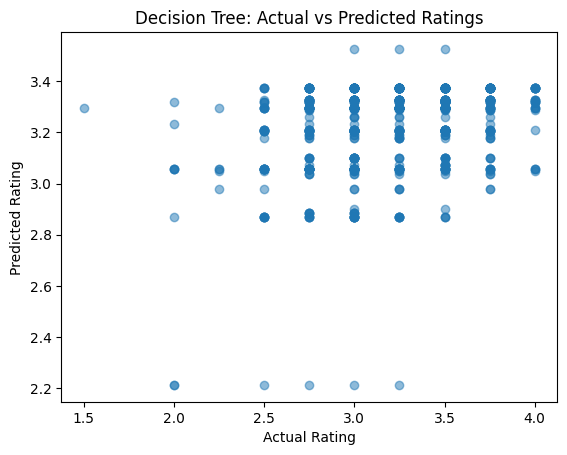

In [29]:
# Plot actual vs predicted ratings for the Decision Tree

plt.scatter(y_test, y_test_pred_dt, alpha=0.5)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Decision Tree: Actual vs Predicted Ratings")

plt.show()

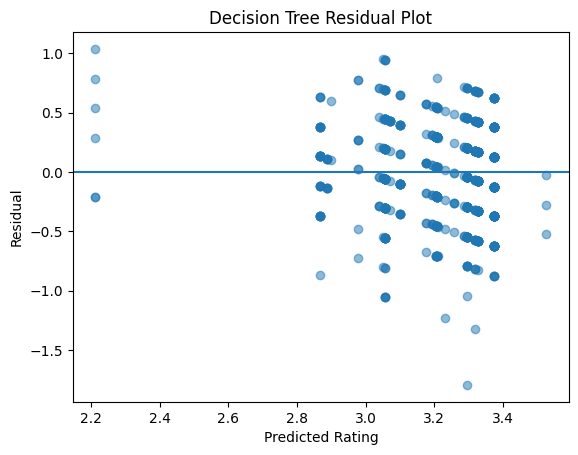

In [30]:
# Plot residuals for the Decision Tree

residuals = y_test - y_test_pred_dt

plt.scatter(y_test_pred_dt, residuals, alpha=0.5)
plt.axhline(0)

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")
plt.title("Decision Tree Residual Plot")

plt.show()

In [31]:
# Import PCA
from sklearn.decomposition import PCA

In [65]:
# Keep the more common sensory characteristics

q_90 = feature_counts.quantile(0.9)

common_features = feature_counts[feature_counts >= q_90].index

pca_features = chars[common_features]

print("Number of sensory features used:", pca_features.shape[1])
display(pca_features.head())

KeyError: "[' cocoa', ' sweet', ' nutty', ' roasty', ' earthy', ' sour', ' floral', ' fatty', ' spicy', ' fruit', ' woody', ' coffee', ' vanilla', ' rich', ' bitter', ' intense', ' molasses', ' caramel', ' spice', ' tart', ' dried fruit', ' grassy', ' fruity', ' brownie', ' dairy', ' banana', ' acidic', ' off', ' vegetal', ' astringent', ' rich cocoa', ' metallic', ' rubbery', ' cherry', ' honey', ' smoke', ' creamy', ' nut', ' sandy', ' smokey', ' mild fruit', ' tobacco', ' hammy', ' pungent', ' dirty', ' burnt', ' melon', ' off notes', ' citrus', ' complex', ' red berry', ' rubber', ' mild bitter', ' basic cocoa', ' marshmallow', ' sticky', ' tangy', ' medicinal', ' sour milk', ' black pepper', ' chemical', ' rum', ' green', ' berry', ' grapes', ' off note', ' strawberry', ' butterscotch', ' licorice', ' gritty', ' ham', ' black licorice', ' fig', ' coconut', ' savory', ' nuts', ' lemon', ' cardboard', ' bland', ' orange', ' bourbon', ' mint', ' bold'] not in index"

In [33]:
# Run PCA on the selected sensory characteristics

pca = PCA(n_components=2)

pca_result = pca.fit_transform(pca_features)

pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

print("PC1 explained variance:", pca.explained_variance_ratio_[0])
print("PC2 explained variance:", pca.explained_variance_ratio_[1])
print("Total explained variance:", pca.explained_variance_ratio_.sum())

display(pca_df.head())

PC1 explained variance: 0.04358525244131846
PC2 explained variance: 0.04185462030641422
Total explained variance: 0.08543987274773268


,PC1,PC2
0,-0.034260,-0.138878
1,-0.068986,-0.099485
2,-0.060006,-0.096338
3,-0.059120,-0.104329
4,0.166866,-0.281600


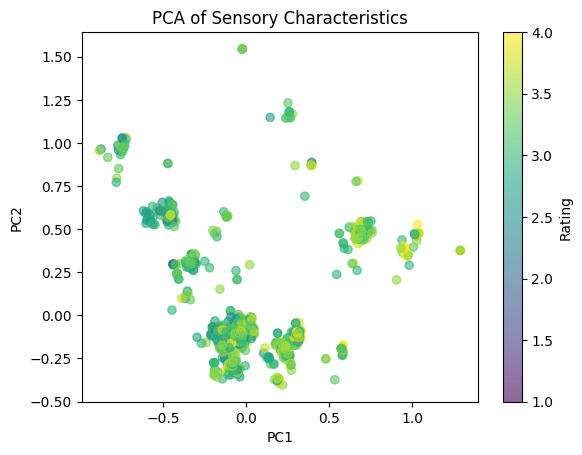

In [34]:
# Plot PC1 vs PC2 and color by rating

plt.scatter(pca_df["PC1"],pca_df["PC2"],c=choc["rating"],alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Sensory Characteristics")

plt.colorbar(label="Rating")
plt.show()

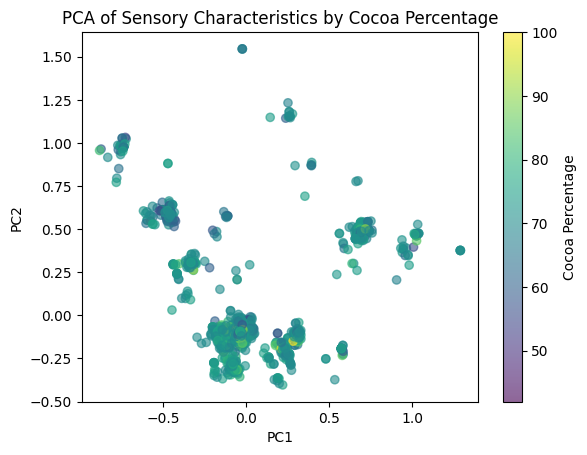

In [35]:
# Plot PC1 vs PC2 and color by cocoa percentage

plt.scatter(pca_df["PC1"], pca_df["PC2"], c=choc["cocoa_numeric"], alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Sensory Characteristics by Cocoa Percentage")

plt.colorbar(label="Cocoa Percentage")
plt.show()